In [1]:
from src.train import model1
from src.train import model2
from src import config
from src.train import utils
from src.data_prep import CargadorDatos

# Modelo Regresion

In [2]:
cargador_modelo1 = CargadorDatos(config.DATA_PROCESSED / "train.csv", config.DATA_PROCESSED / "test.csv", columnas_excluir=["nivel_demanda"])
X_train, y_train, X_test, y_test = cargador_modelo1.obtener_datos()

In [3]:
modeloregresiondemanda = model1.ModeloRegresionDemanda(X_train, y_train, 3, 0.1,128,200)

In [4]:
modeloregresiondemanda.creacion_modelo()

In [5]:
resultado = modeloregresiondemanda.entrenamiento_modelo()

Epoch 1/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 65859.0547 - val_loss: 48865.1914
Epoch 2/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 29734.1895 - val_loss: 23481.4531
Epoch 3/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 19487.9922 - val_loss: 15890.9229
Epoch 4/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 13915.6270 - val_loss: 12303.2070
Epoch 5/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 12300.2324 - val_loss: 11535.5332
Epoch 6/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11804.3408 - val_loss: 11141.0723
Epoch 7/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11351.7910 - val_loss: 10761.2158
Epoch 8/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10972.8613 - val_loss: 10254.5479
Epoch 9/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10354.6963 - val_loss: 9644.4189
Epoch 10/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9745.3125 - val_loss: 9014.4443
Epoch 11/200
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9280.5654 -

In [6]:
perdidas_modelo1 = utils.EvaluacionPerdidasRegresion(resultado)

In [7]:
perdidas_modelo1.perdidas()

,loss,val_loss
0,65859.054688,48865.191406
1,29734.189453,23481.453125
2,19487.992188,15890.922852
3,13915.626953,12303.207031
4,12300.232422,11535.533203
...,...,...
195,5423.093262,5240.895508
196,5442.344238,5248.682617
197,5572.438965,5255.071777
198,5399.853516,5281.656738


<Axes: >

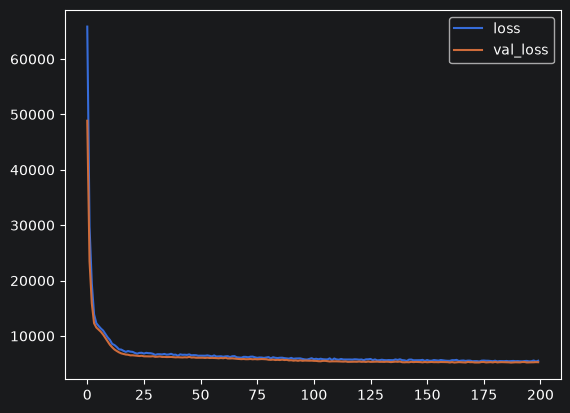

In [8]:
perdidas_modelo1.grafica_perdidas()

In [9]:
predicciones_modelo1 = modeloregresiondemanda.predecir(X_test)

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [10]:
metricas_modelo1 = utils.Metricas(y_test, predicciones_modelo1)

In [11]:
metricas_modelo1.mae()

46.96143341064453

In [12]:
metricas_modelo1.diferecia_porc_mae()

,cnt
0,0.110497
1,0.533653
2,11.740358
3,0.089280
4,3.612418
...,...
3471,2.762437
3472,0.552487
3473,0.479198
3474,0.176547


In [13]:
metricas_modelo1.mrse()

np.float64(70.57488888695646)

In [14]:
metricas_modelo1.diferencia_porc_mrse()

,cnt
0,0.166059
1,0.801987
2,17.643722
3,0.134173
4,5.428838
...,...
3471,4.151464
3472,0.830293
3473,0.720152
3474,0.265319


In [15]:
metricas_modelo1.varianza_explicada()

0.8429567217826843

In [16]:
metricas_modelo1.r2()

0.8427048921585083

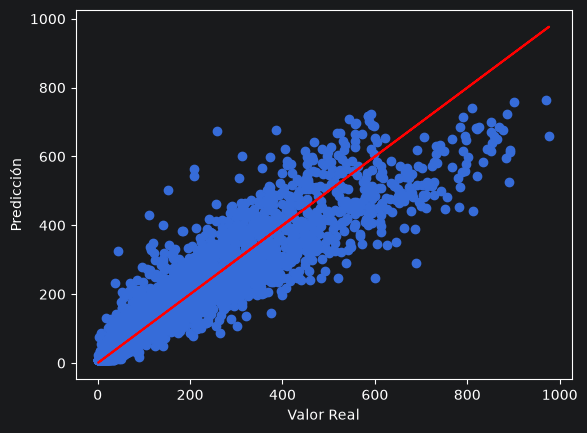

In [17]:
metricas_modelo1.grafico_valorreal_prediccion()

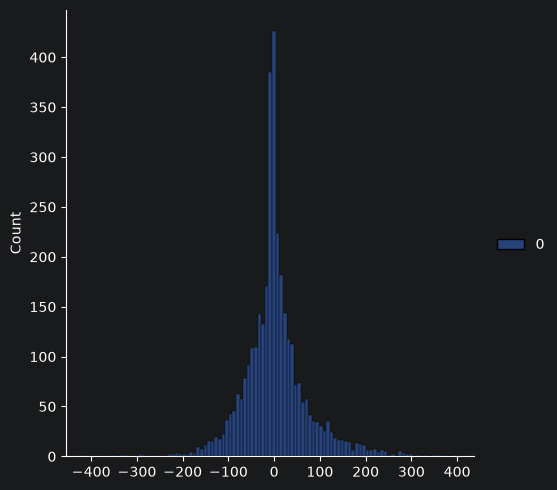

In [18]:
metricas_modelo1.grafico_error()

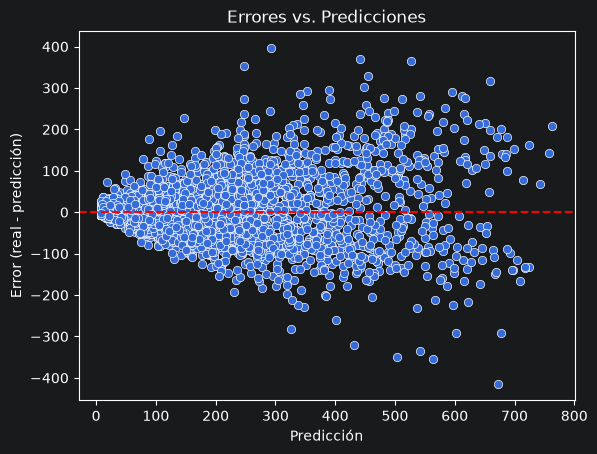

In [19]:
metricas_modelo1.grafico_errores_predicciones()

In [20]:
modeloregresiondemanda.guardar_modelo()

# Modelo Clasificacion

In [21]:
cargador_modelo2 = CargadorDatos(config.DATA_PROCESSED / "train.csv", config.DATA_PROCESSED / "test.csv", columna_objetivo="nivel_demanda",
        columnas_excluir=['cnt'])
X_train, y_train, X_test, y_test = cargador_modelo2.obtener_datos()

In [22]:
modeloclasificaciondemanda = model2.ModeloClasificacionDemanda(X_train, y_train, 3, 0.1, 128, 200)

In [23]:
modeloclasificaciondemanda.creacion_modelo()

<Sequential name=sequential_1, built=True>

In [24]:
resultado_clasificacion = modeloclasificaciondemanda.entrenamiento_modelo(X_train, y_train, X_test, y_test)

Epoch 1/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4294 - loss: 1.2372 - val_accuracy: 0.6338 - val_loss: 0.8538
Epoch 2/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6358 - loss: 0.8184 - val_accuracy: 0.6939 - val_loss: 0.6875
Epoch 3/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6895 - loss: 0.7107 - val_accuracy: 0.7284 - val_loss: 0.6170
Epoch 4/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7112 - loss: 0.6581 - val_accuracy: 0.7434 - val_loss: 0.5832
Epoch 5/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7270 - loss: 0.6218 - val_accuracy: 0.7503 - val_loss: 0.5686
Epoch 6/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7335 - loss: 0.6095 - val_accuracy: 0.7465 - val_loss: 0.5618
Epoch 7/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7356 - loss: 0.5981 - val_accuracy: 0.7480 - val_loss: 0.5555
Epoch 8/200
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7412 - loss: 0.5870 - val_acc

In [25]:
perdidas_modelo2 = utils.EvaluacionPerdidasClasificacion(resultado_clasificacion)

In [26]:
perdidas_modelo2.perdidas()

,accuracy,loss,val_accuracy,val_loss
0,0.429404,1.237182,0.633774,0.853755
1,0.635834,0.818389,0.693901,0.687525
2,0.689491,0.710662,0.728423,0.617048
3,0.711213,0.658121,0.743383,0.583189
4,0.727037,0.621842,0.750288,0.568612
...,...,...,...,...
81,0.789110,0.468804,0.762946,0.518506
82,0.789830,0.464214,0.763809,0.517630
83,0.790693,0.465104,0.762083,0.518066
84,0.793426,0.461792,0.765535,0.515448


<Axes: >

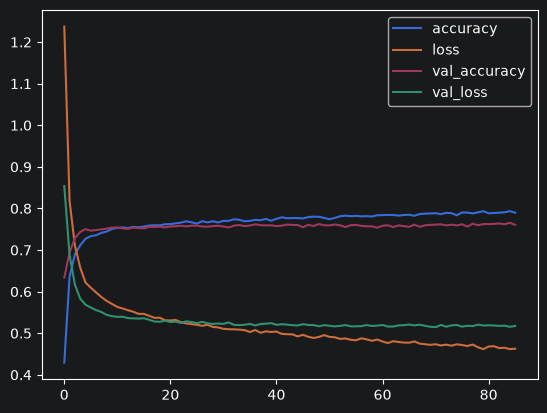

In [27]:
perdidas_modelo2.grafica_perdidas()

In [28]:
predicciones_prob = modeloclasificaciondemanda.predecir(X_test)

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


In [29]:
predicciones_clase = predicciones_prob.argmax(axis=1)

In [30]:
metricas_modelo2 = utils.MetricasClasificacion(y_test, predicciones_clase)

In [31]:
metricas_modelo2.accurancy()

0.760644418872267

In [32]:
metricas_modelo2.matriz_confusion()

array([[790,  61,   1,   0],
       [111, 622, 184,   9],
       [  1, 138, 584, 135],
       [  0,   6, 186, 648]])

In [33]:
metricas_modelo2.reporte_clasificacion()

'              precision    recall  f1-score   support\n\n           0       0.88      0.93      0.90       852\n           1       0.75      0.67      0.71       926\n           2       0.61      0.68      0.64       858\n           3       0.82      0.77      0.79       840\n\n    accuracy                           0.76      3476\n   macro avg       0.76      0.76      0.76      3476\nweighted avg       0.76      0.76      0.76      3476\n'

In [34]:
metricas_modelo2.matriz_confusion()

array([[790,  61,   1,   0],
       [111, 622, 184,   9],
       [  1, 138, 584, 135],
       [  0,   6, 186, 648]])

In [35]:
modeloclasificaciondemanda.guardar_modelo()

Modelo guardado
